In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/XAI-Stability-Bench/datasets/bank-full.csv",
    sep=";"
)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.shape

(45211, 17)

In [4]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [6]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [7]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [8]:
df["y"] = df["y"].map({
    "yes": 1,
    "no": 0
})

In [9]:
df["y"].value_counts()

,count
y,
0,39922
1,5289


In [10]:
categorical_cols = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome"
]

In [11]:
df = pd.get_dummies(
    df,
    columns=categorical_cols,
    dtype=int
)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 52 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   age                  45211 non-null  int64
 1   balance              45211 non-null  int64
 2   day                  45211 non-null  int64
 3   duration             45211 non-null  int64
 4   campaign             45211 non-null  int64
 5   pdays                45211 non-null  int64
 6   previous             45211 non-null  int64
 7   y                    45211 non-null  int64
 8   job_admin.           45211 non-null  int64
 9   job_blue-collar      45211 non-null  int64
 10  job_entrepreneur     45211 non-null  int64
 11  job_housemaid        45211 non-null  int64
 12  job_management       45211 non-null  int64
 13  job_retired          45211 non-null  int64
 14  job_self-employed    45211 non-null  int64
 15  job_services         45211 non-null  int64
 16  job_student          4

In [13]:
X = df.drop("y", axis=1)
y = df["y"]

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [16]:
print(X_train.shape)
print(X_test.shape)

(36168, 51)
(9043, 51)


##Logistic Regression

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [18]:
y_pred = model.predict(X_test)

In [19]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.8987
Precision: 0.6538
Recall   : 0.3410
F1 Score : 0.4482


[[7755  197]
 [ 719  372]]


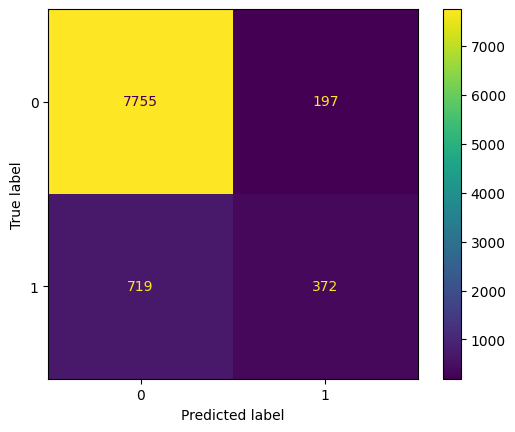

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

In [21]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.98      0.94      7952
           1       0.65      0.34      0.45      1091

    accuracy                           0.90      9043
   macro avg       0.78      0.66      0.70      9043
weighted avg       0.88      0.90      0.88      9043



In [22]:
from sklearn.metrics import roc_auc_score

lr_auc = roc_auc_score(
    y_test,
    model.predict_proba(X_test)[:, 1]
)

print(f"ROC-AUC: {lr_auc:.4f}")

ROC-AUC: 0.9046


In [23]:
import joblib

joblib.dump(
    model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/bank_logistic_regression.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/bank_logistic_regression.pkl']

In [24]:
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": round(accuracy, 4),
    "Precision": round(precision, 4),
    "Recall": round(recall, 4),
    "F1 Score": round(f1, 4),
    "ROC-AUC": round(lr_auc, 4)
}

##Decision Tree

In [25]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [26]:
dt_pred = dt_model.predict(X_test)

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1 Score : {dt_f1:.4f}")

Accuracy : 0.8731
Precision: 0.4747
Recall   : 0.4904
F1 Score : 0.4824


[[7360  592]
 [ 556  535]]


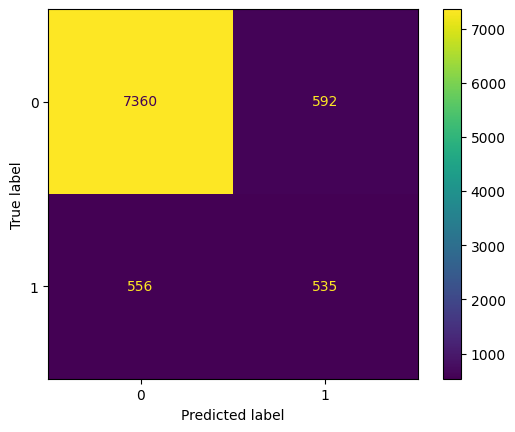

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, dt_pred)

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred
)

In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           0       0.93      0.93      0.93      7952
           1       0.47      0.49      0.48      1091

    accuracy                           0.87      9043
   macro avg       0.70      0.71      0.71      9043
weighted avg       0.87      0.87      0.87      9043



In [30]:
from sklearn.metrics import roc_auc_score

dt_auc = roc_auc_score(
    y_test,
    dt_model.predict_proba(X_test)[:, 1]
)

print(f"ROC-AUC: {dt_auc:.4f}")

ROC-AUC: 0.7080


In [31]:
import joblib

joblib.dump(
    dt_model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/bank_decision_tree.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/bank_decision_tree.pkl']

In [32]:
dt_results = {
    "Model": "Decision Tree",
    "Accuracy": round(dt_accuracy, 4),
    "Precision": round(dt_precision, 4),
    "Recall": round(dt_recall, 4),
    "F1 Score": round(dt_f1, 4),
    "ROC-AUC": round(dt_auc, 4)
}

In [33]:
dt_results

{'Model': 'Decision Tree',
 'Accuracy': 0.8731,
 'Precision': 0.4747,
 'Recall': 0.4904,
 'F1 Score': 0.4824,
 'ROC-AUC': np.float64(0.708)}

##Random Forest

In [34]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [35]:
rf_pred = rf_model.predict(X_test)

In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")

Accuracy : 0.9056
Precision: 0.6782
Recall   : 0.4134
F1 Score : 0.5137


[[7738  214]
 [ 640  451]]


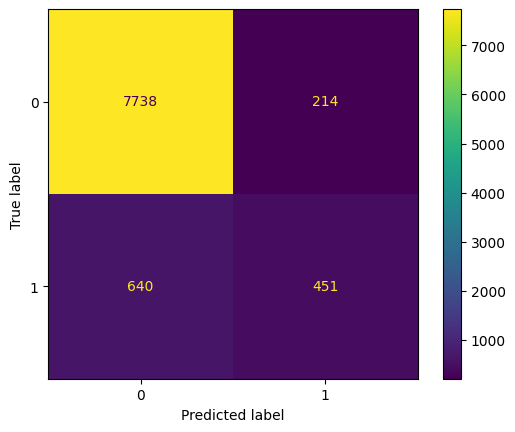

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, rf_pred)

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred
)

In [38]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.92      0.97      0.95      7952
           1       0.68      0.41      0.51      1091

    accuracy                           0.91      9043
   macro avg       0.80      0.69      0.73      9043
weighted avg       0.89      0.91      0.90      9043



In [39]:
from sklearn.metrics import roc_auc_score

rf_auc = roc_auc_score(
    y_test,
    rf_model.predict_proba(X_test)[:, 1]
)

print(f"ROC-AUC: {rf_auc:.4f}")

ROC-AUC: 0.9272


In [40]:
import joblib

joblib.dump(
    rf_model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/bank_random_forest.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/bank_random_forest.pkl']

In [41]:
rf_results = {
    "Model": "Random Forest",
    "Accuracy": round(rf_accuracy, 4),
    "Precision": round(rf_precision, 4),
    "Recall": round(rf_recall, 4),
    "F1 Score": round(rf_f1, 4),
    "ROC-AUC": round(rf_auc, 4)
}

In [42]:
rf_results

{'Model': 'Random Forest',
 'Accuracy': 0.9056,
 'Precision': 0.6782,
 'Recall': 0.4134,
 'F1 Score': 0.5137,
 'ROC-AUC': np.float64(0.9272)}

##XGBoost

In [43]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [44]:
xgb_pred = xgb_model.predict(X_test)

In [45]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)

print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")

Accuracy : 0.9057
Precision: 0.6374
Recall   : 0.5060
F1 Score : 0.5641


[[7638  314]
 [ 539  552]]


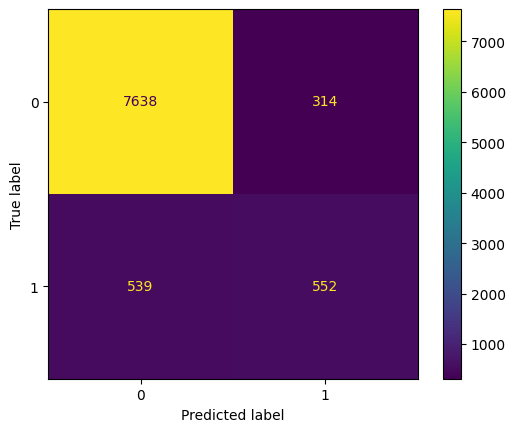

In [46]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, xgb_pred)

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred
)

In [47]:
from sklearn.metrics import classification_report

print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.93      0.96      0.95      7952
           1       0.64      0.51      0.56      1091

    accuracy                           0.91      9043
   macro avg       0.79      0.73      0.76      9043
weighted avg       0.90      0.91      0.90      9043



In [48]:
from sklearn.metrics import roc_auc_score

xgb_auc = roc_auc_score(
    y_test,
    xgb_model.predict_proba(X_test)[:, 1]
)

print(f"ROC-AUC: {xgb_auc:.4f}")

ROC-AUC: 0.9317


In [49]:
import joblib

joblib.dump(
    xgb_model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/bank_xgboost.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/bank_xgboost.pkl']

In [50]:
xgb_results = {
    "Model": "XGBoost",
    "Accuracy": round(xgb_accuracy, 4),
    "Precision": round(xgb_precision, 4),
    "Recall": round(xgb_recall, 4),
    "F1 Score": round(xgb_f1, 4),
    "ROC-AUC": round(xgb_auc, 4)
}

In [51]:
import pandas as pd

results_df = pd.DataFrame([
    lr_results,
    dt_results,
    rf_results,
    xgb_results
])

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8987,0.6538,0.3410,0.4482,0.9046
1,Decision Tree,0.8731,0.4747,0.4904,0.4824,0.7080
2,Random Forest,0.9056,0.6782,0.4134,0.5137,0.9272
3,XGBoost,0.9057,0.6374,0.5060,0.5641,0.9317


In [52]:
results_df.to_csv(
    "/content/drive/MyDrive/XAI-Stability-Bench/results/bank_model_comparison.csv",
    index=False
)

In [53]:
import os

os.path.exists(
    "/content/drive/MyDrive/XAI-Stability-Bench/results/bank_model_comparison.csv"
)

True